# Assignment No:04

Name:Bhapkar Rajnandini 

EN24107014

TY-AIDS(A)

Title:-Build a simple Rule-based Classifier or Random Forest Model to evaluate password strength based on
length, special characters, and dictionary words.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [3]:
df = pd.read_csv("passwords_dataset.csv")

In [4]:
df.head()

,Password,Has Lowercase,Has Uppercase,Has Special Character,Length,Strength
0,<%r?.,True,False,True,5,Weak
1,l(d_l,True,False,True,5,Weak
2,"|+Z)kDTRYo:q{""(",True,True,True,15,Strong
3,gwcNB[oS5!n%OPJ,True,True,True,15,Strong
4,^vXjCCP6,True,True,True,8,Strong


In [5]:
df.isnull().sum()

Password                 0
Has Lowercase            0
Has Uppercase            0
Has Special Character    0
Length                   0
Strength                 0
dtype: int64

In [6]:
df.columns

Index(['Password', 'Has Lowercase', 'Has Uppercase', 'Has Special Character',
       'Length', 'Strength'],
      dtype='object')

In [7]:
X = df[["Has Lowercase","Has Uppercase","Has Special Character","Length"]]
y = df["Strength"]

In [8]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,
random_state=42,stratify=y)

In [9]:
model = RandomForestClassifier(n_estimators=100,random_state=42)

In [10]:
model.fit(X_train, y_train)
print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [11]:
y_pred = model.predict(X_test)
print("Predictions:")
print(y_pred[:10])

Predictions:
['Strong' 'Strong' 'Medium' 'Medium' 'Strong' 'Strong' 'Strong' 'Strong'
 'Medium' 'Strong']


In [12]:
accuracy = accuracy_score(y_test, y_pred)
print("MODEL PERFORMANCE")
print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

MODEL PERFORMANCE
Accuracy: 0.9995
Accuracy (%): 99.95


In [13]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

      Medium       1.00      1.00      1.00       370
      Strong       1.00      1.00      1.00      1190
        Weak       1.00      1.00      1.00       440

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [14]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 370    0    0]
 [   0 1190    0]
 [   0    1  439]]


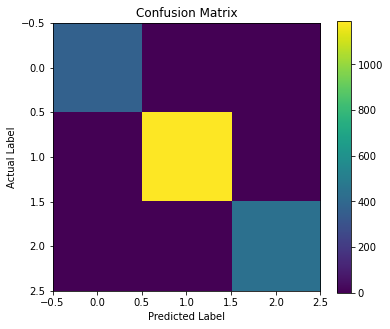

In [15]:
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.colorbar()
plt.show()

In [16]:
new_password = [[
1, # Has Lowercase
1, # Has Uppercase
1, # Has Special Character
1 # Length
]]
prediction = model.predict(new_password)
print("NEW PASSWORD PREDICTION")
print("Predicted Strength:", prediction[0])

NEW PASSWORD PREDICTION
Predicted Strength: Weak


In [17]:
new_password = [[1, 1, 1, 12]]
prediction = model.predict(new_password)
print("Password Strength:", prediction[0])

Password Strength: Strong
